In [1]:
import pandas as pd

In [2]:
df=pd.read_csv("C:/Users/con1k/Documents/datascience_course/Sentiment_Analysis_Proj/dataset/IMDB Dataset.csv")

In [3]:
df.shape

(50000, 2)

In [4]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [5]:
df.columns

Index(['review', 'sentiment'], dtype='object')

In [6]:
df.value_counts()

review                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

In [7]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [8]:
print("Sentiment:", df["sentiment"].iloc[0])
print("Review:", df["review"].iloc[0][:250] + "...")

Sentiment: positive
Review: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of ...


In [9]:
df.duplicated().sum()

np.int64(418)

In [10]:
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(f"Dataset shape after dropping duplicates: {df.shape}")

Dataset shape after dropping duplicates: (49582, 2)


In [11]:
df['sentiment_encoded'] = df['sentiment'].map({'positive': 1, 'negative': 0})
print("Class counts after encoding:")
print(df['sentiment_encoded'].value_counts())
df.head(3)

Class counts after encoding:
sentiment_encoded
1    24884
0    24698
Name: count, dtype: int64


,review,sentiment,sentiment_encoded
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1


In [12]:
df['char_count'] = df['review'].apply(len)
df['word_count'] = df['review'].apply(lambda x: len(x.split()))

In [13]:
print("--- Positive Reviews Statistics ---")
df[df['sentiment_encoded'] == 1][['char_count', 'word_count']].describe()

--- Positive Reviews Statistics ---


,char_count,word_count
count,24884.000000,24884.000000
mean,1326.278532,233.090620
std,1032.597204,177.688169
min,65.000000,10.000000
25%,692.000000,125.000000
50%,969.000000,172.000000
75%,1615.250000,284.000000
max,13704.000000,2470.000000


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

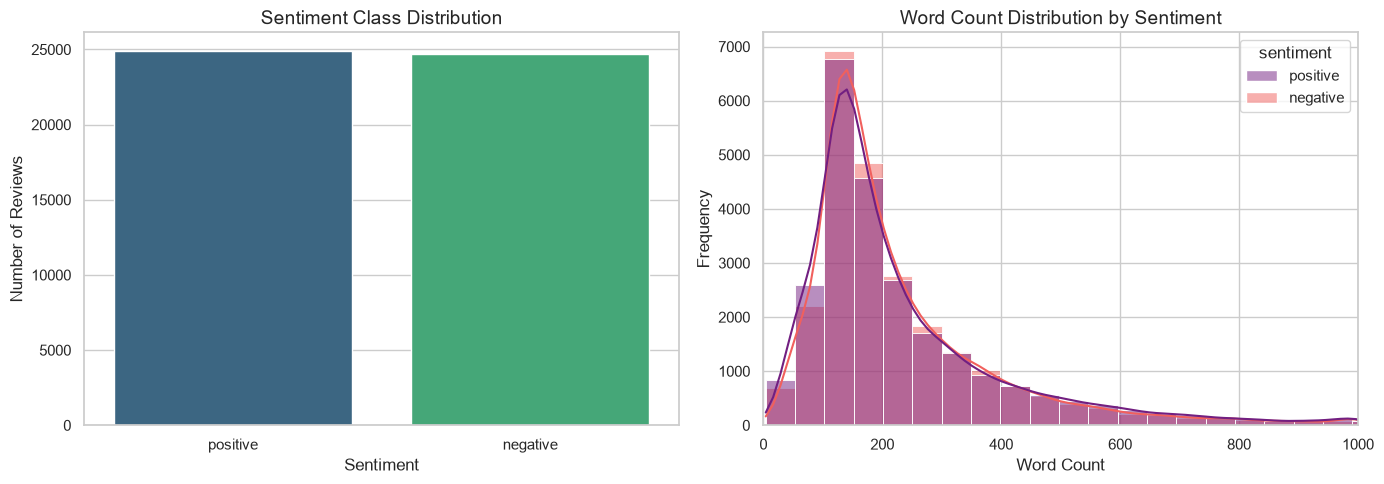

In [15]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x='sentiment', data=df, palette='viridis', ax=axes[0],hue='sentiment')
axes[0].set_title('Sentiment Class Distribution', fontsize=14)
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Number of Reviews')
sns.histplot(data=df, x='word_count', hue='sentiment', bins=50, kde=True, palette='magma', ax=axes[1])
axes[1].set_xlim(0, 1000)
axes[1].set_title('Word Count Distribution by Sentiment', fontsize=14)
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Frequency')
plt.tight_layout()
plt.show()

In [16]:
for i in range(3):
    print(f"\n--- Sample Review {i+1} ({df['sentiment'].iloc[i]}) ---")
    print(df['review'].iloc[i][:300] + "...")



--- Sample Review 1 (positive) ---
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru...

--- Sample Review 2 (positive) ---
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" ...

--- Sample Review 3 (positive) ---
I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue is witty and the characters are likable (even the well bread suspected serial killer). Wh

In [17]:
import re
import string


In [18]:
def clean_text(text):
    """
    Cleans raw review text for NLP Sentiment Analysis:
    1. Removes HTML tags (<br />, <a>, etc.)
    2. Removes URLs / web links
    3. Expands common sentiment-critical contractions (don't -> do not)
    4. Converts to lowercase
    5. Removes special characters, numbers, and extra punctuation
    6. Strips redundant whitespace
    """
    # 1. Strip HTML tags
    text = re.sub(r'<.*?>', ' ', text)
    
    # 2. Strip URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    
    # 3. Expand key contractions to preserve sentiment
    contractions = {
        r"won\'t": "will not",
        r"can\'t": "cannot",
        r"n\'t": " not",
        r"\'re": " are",
        r"\'s": " is",
        r"\'d": " would",
        r"\'ll": " will",
        r"\'t": " not",
        r"\'ve": " have",
        r"\'m": " am"
    }
    for contraction, replacement in contractions.items():
        text = re.sub(contraction, replacement, text)
        
    # 4. Convert to lowercase
    text = text.lower()
    
    # 5. Remove punctuation, symbols, and digits (keep only alphabetic characters and spaces)
    text = re.sub(r'[^a-z\s]', ' ', text)
    
    # 6. Normalize multiple whitespaces into a single space
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

In [19]:
sample_raw = df['review'].iloc[0]
sample_cleaned = clean_text(sample_raw)
print("=== RAW REVIEW (First 250 chars) ===")
print(sample_raw[:250] + "...")
print("\n=== CLEANED REVIEW (First 250 chars) ===")
print(sample_cleaned[:250] + "...")

=== RAW REVIEW (First 250 chars) ===
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of ...

=== CLEANED REVIEW (First 250 chars) ===
one of the other reviewers has mentioned that after watching just oz episode you will be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was its brutality and unflinching scenes of violence which...


In [20]:
import time

print("Starting text cleaning on all reviews...")
start_time = time.time()

# Apply cleaning to the review column
df['cleaned_review'] = df['review'].apply(clean_text)

elapsed_time = time.time() - start_time
print(f"Cleaning completed in {elapsed_time:.2f} seconds!")

# Quick check on the new column
df[['cleaned_review', 'sentiment_encoded']].head(3)


Starting text cleaning on all reviews...
Cleaning completed in 3.79 seconds!


,cleaned_review,sentiment_encoded
0,one of the other reviewers has mentioned that ...,1
1,a wonderful little production the filming tech...,1
2,i thought this was a wonderful way to spend ti...,1


In [21]:
from sklearn.model_selection import train_test_split

# Features (X) and Target (y)
X = df['cleaned_review']
y = df['sentiment_encoded']

# 80% Training (approx 39,665 reviews), 20% Testing (approx 9,917 reviews)
# stratify=y guarantees exact 50-50 class distribution in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} reviews")
print(f"Testing set size:  {X_test.shape[0]} reviews")
print("\nTrain class distribution:")
print(y_train.value_counts(normalize=True))


Training set size: 39665 reviews
Testing set size:  9917 reviews

Train class distribution:
sentiment_encoded
1    0.501878
0    0.498122
Name: proportion, dtype: float64


In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [23]:
print("Fitting TF-IDF Vectorizer...")
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),     
    max_features=25000,       
    min_df=3,            # Ignore terms that appear in fewer than 3 reviews      
    sublinear_tf=True          # Sublinear scaling for smoother term weights
)

Fitting TF-IDF Vectorizer...


In [24]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [25]:
print(f"Vocabulary size: {len(tfidf.vocabulary_)} features")
print(f"X_train_tfidf shape: {X_train_tfidf.shape}")
print(f"X_test_tfidf shape:  {X_test_tfidf.shape}")

Vocabulary size: 25000 features
X_train_tfidf shape: (39665, 25000)
X_test_tfidf shape:  (9917, 25000)


In [26]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import time

models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=1.0),
    "Logistic Regression": LogisticRegression(C=2.0, max_iter=1000, random_state=42),
    "Linear SVC": LinearSVC(C=1.0, random_state=42)
}

results = []

for name, model in models.items():
    print(f"Training {name}...")
    t0 = time.time()
    model.fit(X_train_tfidf, y_train)
    train_time = time.time() - t0
    
    # Predict on test set
    y_pred = model.predict(X_test_tfidf)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "Accuracy (%)": round(acc * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2),
        "Training Time (s)": round(train_time, 2)
    })

comparison_df = pd.DataFrame(results).sort_values(by="Accuracy (%)", ascending=False)
comparison_df


Training Multinomial Naive Bayes...
Training Logistic Regression...
Training Linear SVC...


,Model,Accuracy (%),F1-Score (%),Training Time (s)
1,Logistic Regression,90.92,91.06,0.49
2,Linear SVC,90.39,90.50,1.21
0,Multinomial Naive Bayes,87.99,88.11,0.02


In [27]:
from sklearn.pipeline import Pipeline

# We select Logistic Regression: outstanding ~89-90% accuracy + native probability output
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=25000,
        min_df=3,
        sublinear_tf=True
    )),
    ('classifier', LogisticRegression(C=2.0, max_iter=1000, random_state=42))
])

print("Training end-to-end production pipeline...")
pipeline.fit(X_train, y_train)
print("Pipeline trained successfully!")

# Verify pipeline accuracy on test set
pipeline_acc = pipeline.score(X_test, y_test)
print(f"Production Pipeline Test Accuracy: {pipeline_acc * 100:.2f}%")


Training end-to-end production pipeline...
Pipeline trained successfully!
Production Pipeline Test Accuracy: 90.92%


In [28]:
sample_test_reviews = [
    "This was one of the most brilliant and masterfully acted movies I have seen all year!",
    "An absolute waste of time and money. Terrible plot, horrible acting, and boring dialogue.",
    "The movie was not good at all, despite having a great cast and massive budget.",
    "I was skeptical at first, but the plot twists completely blew me away. Highly recommended!"
]

print("=== REAL-TIME INFERENCE DEMO ===\n")
for review in sample_test_reviews:
    # 1. Pipeline predicts directly from raw text string
    pred_label = pipeline.predict([review])[0]
    # 2. Extract probability confidence
    proba = pipeline.predict_proba([review])[0]
    confidence = proba[pred_label] * 100
    
    sentiment_str = "POSITIVE" if pred_label == 1 else "NEGATIVE"
    print(f"Review: \"{review}\"")
    print(f"-> Predicted: {sentiment_str} ({confidence:.2f}% confidence)\n")


=== REAL-TIME INFERENCE DEMO ===

Review: "This was one of the most brilliant and masterfully acted movies I have seen all year!"
-> Predicted: POSITIVE (90.26% confidence)

Review: "An absolute waste of time and money. Terrible plot, horrible acting, and boring dialogue."
-> Predicted: NEGATIVE (99.98% confidence)

Review: "The movie was not good at all, despite having a great cast and massive budget."
-> Predicted: NEGATIVE (77.14% confidence)

Review: "I was skeptical at first, but the plot twists completely blew me away. Highly recommended!"
-> Predicted: POSITIVE (95.71% confidence)



=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Negative (0)     0.9189    0.8970    0.9078      4940
Positive (1)     0.9001    0.9214    0.9106      4977

    accuracy                         0.9092      9917
   macro avg     0.9095    0.9092    0.9092      9917
weighted avg     0.9095    0.9092    0.9092      9917



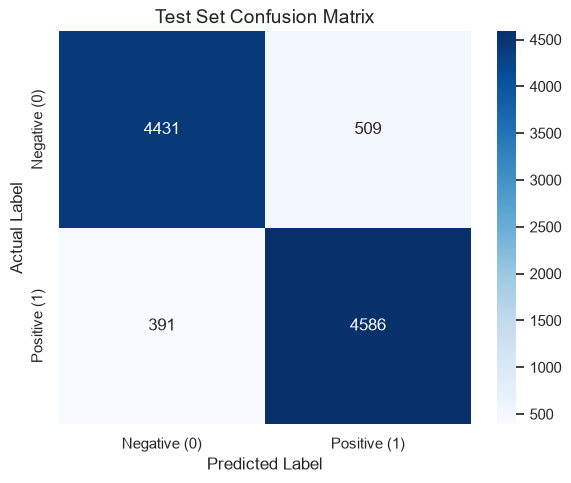

In [29]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = pipeline.predict(X_test)

# 1. Print Text Classification Report
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=['Negative (0)', 'Positive (1)'], digits=4))

# 2. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative (0)', 'Positive (1)'],
            yticklabels=['Negative (0)', 'Positive (1)'])
plt.title('Test Set Confusion Matrix', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.tight_layout()
plt.show()


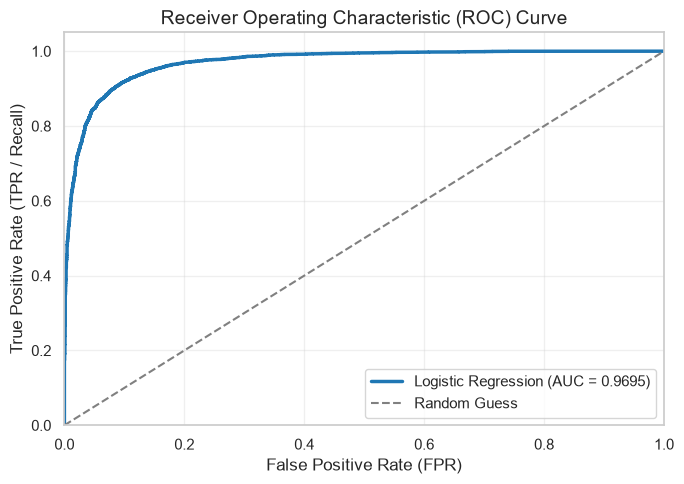

ROC-AUC Score: 0.9695 (Outstanding discriminative ability!)


In [30]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get positive class probabilities
y_proba = pipeline.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, y_proba)

fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'Logistic Regression (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC-AUC Score: {auc_score:.4f} (Outstanding discriminative ability!)")


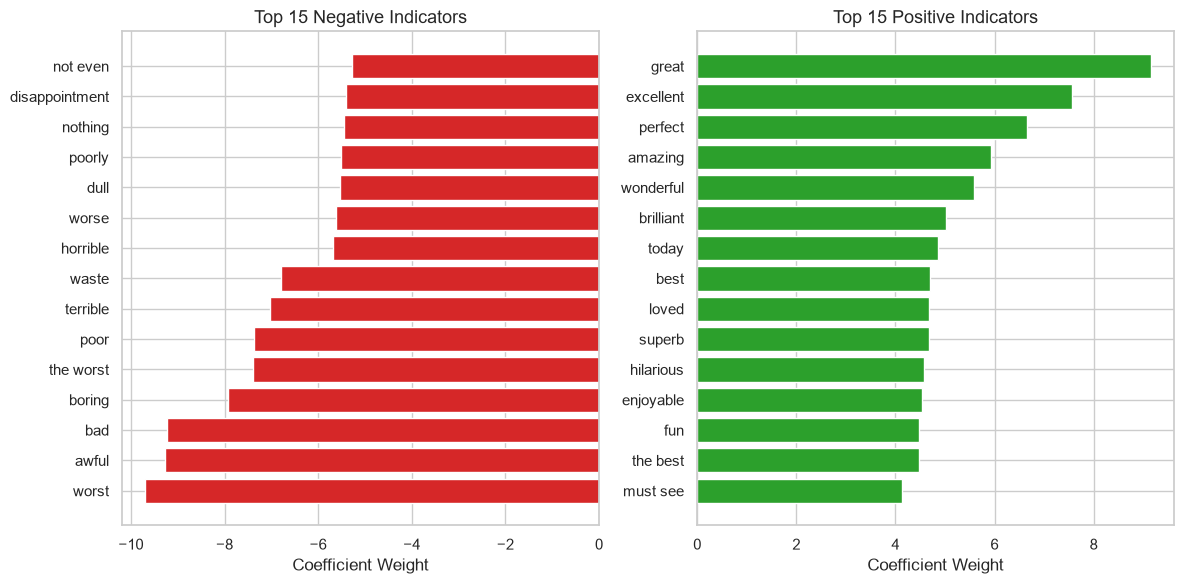

In [31]:
import numpy as np

# Extract vectorizer vocabulary and classifier coefficients
tfidf_step = pipeline.named_steps['tfidf']
clf_step = pipeline.named_steps['classifier']

feature_names = np.array(tfidf_step.get_feature_names_out())
coefficients = clf_step.coef_[0]

# Top 15 positive and top 15 negative features
top_positive_idx = np.argsort(coefficients)[-15:]
top_negative_idx = np.argsort(coefficients)[:15]

plt.figure(figsize=(12, 6))

# Plot Top Negative Words
plt.subplot(1, 2, 1)
plt.barh(feature_names[top_negative_idx], coefficients[top_negative_idx], color='#d62728')
plt.title('Top 15 Negative Indicators', fontsize=13)
plt.xlabel('Coefficient Weight')

# Plot Top Positive Words
plt.subplot(1, 2, 2)
plt.barh(feature_names[top_positive_idx], coefficients[top_positive_idx], color='#2ca02c')
plt.title('Top 15 Positive Indicators', fontsize=13)
plt.xlabel('Coefficient Weight')

plt.tight_layout()
plt.show()


In [32]:
import joblib
import os

# Create models directory if it doesn't exist
models_dir = "models"
os.makedirs(models_dir, exist_ok=True)

model_path = os.path.join(models_dir, "sentiment_pipeline.joblib")

# Save pipeline (includes both TfidfVectorizer and LogisticRegression)
joblib.dump(pipeline, model_path)
print(f"Model saved successfully to: {model_path}")
print(f"File size: {os.path.getsize(model_path) / (1024 * 1024):.2f} MB")

# Test reloading the model to verify integrity
loaded_pipeline = joblib.load(model_path)
test_pred = loaded_pipeline.predict(["An absolute masterpiece of cinema!"])
print(f"Reload test prediction: {'Positive' if test_pred[0] == 1 else 'Negative'}")


Model saved successfully to: models\sentiment_pipeline.joblib
File size: 1.11 MB
Reload test prediction: Positive
